Original: (200000, 200)
Class 0: 179902  Class 1: 20098

Reduced class 0: (60000, 200)

Undersampled dataset: (80098, 200)
Class 0: 60000  Class 1: 20098
Positive rate: 0.25092  (was 0.10049)

  Mean deviation: max=0.0098  mean=0.0028
  Std ratio:      min=0.9947  max=1.0053  mean=1.0000


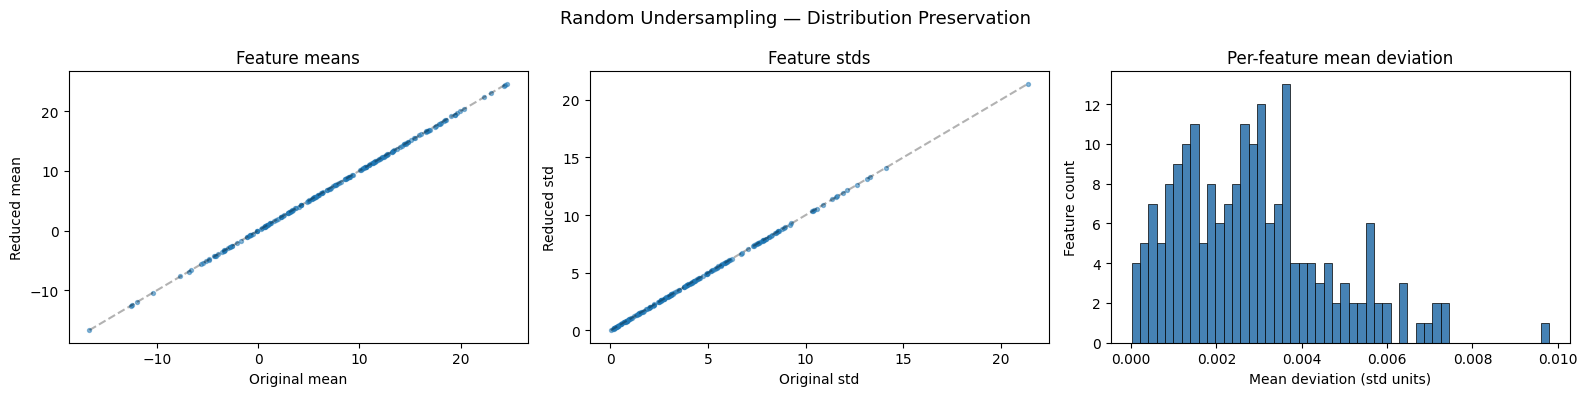


  X_all: (80098, 200)  y_all: (80098,)
  X_kaggle_test: (200000, 200)  test_ids: (200000,)
  Ready for structural split.


In [1]:
# ====================== RANDOM UNpython
# ====================== RANDOM UNDERSAMPLE CLASS 0 ======================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ====================== READ CSV ======================

data = pd.read_csv('/kaggle/input/competitions/santander-customer-transaction-prediction/train.csv')
test_data = pd.read_csv('/kaggle/input/competitions/santander-customer-transaction-prediction/test.csv')

X_all = data.drop(columns=['target', 'ID_code']).values
y_all = data['target'].values
X_kaggle_test = test_data.drop(columns=['ID_code']).values
test_ids = test_data['ID_code'].values

print(f"Original: {X_all.shape}")
print(f"Class 0: {(y_all==0).sum()}  Class 1: {(y_all==1).sum()}")


# ====================== SETTINGS ======================

TARGET_CLASS0 = 60000

# ====================== SEPARATE CLASSES ======================

mask_c0 = (y_all == 0)
mask_c1 = (y_all == 1)

X_c0 = X_all[mask_c0]
X_c1 = X_all[mask_c1]
y_c1 = y_all[mask_c1]


# ====================== RANDOM UNDERSAMPLE CLASS 0 ======================

rng = np.random.RandomState(42)
keep_idx = rng.choice(len(X_c0), size=TARGET_CLASS0, replace=False)
X_c0_reduced = X_c0[keep_idx]

print(f"\nReduced class 0: {X_c0_reduced.shape}")


# ====================== REBUILD DATASET ======================

X_all = np.vstack([X_c0_reduced, X_c1])
y_all = np.concatenate([np.zeros(len(X_c0_reduced)), y_c1])

shuffle_idx = rng.permutation(len(X_all))
X_all = X_all[shuffle_idx]
y_all = y_all[shuffle_idx]

print(f"\nUndersampled dataset: {X_all.shape}")
print(f"Class 0: {(y_all==0).sum()}  Class 1: {(y_all==1).sum()}")
print(f"Positive rate: {y_all.mean():.5f}  (was {mask_c1.sum() / len(mask_c1):.5f})")


# ====================== VERIFY ======================

orig_mean = X_c0.mean(axis=0)
new_mean = X_c0_reduced.mean(axis=0)
orig_std = X_c0.std(axis=0) + 1e-8

mean_dev = np.abs(new_mean - orig_mean) / orig_std
std_ratio = (X_c0_reduced.std(axis=0) + 1e-8) / orig_std

print(f"\n  Mean deviation: max={mean_dev.max():.4f}  mean={mean_dev.mean():.4f}")
print(f"  Std ratio:      min={std_ratio.min():.4f}  max={std_ratio.max():.4f}  mean={std_ratio.mean():.4f}")


# ====================== DIAGRAMS ======================

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(orig_mean, new_mean, s=8, alpha=0.5)
lims = [orig_mean.min(), orig_mean.max()]
axes[0].plot(lims, lims, 'k--', alpha=0.3)
axes[0].set_xlabel('Original mean')
axes[0].set_ylabel('Reduced mean')
axes[0].set_title('Feature means')

axes[1].scatter(orig_std, X_c0_reduced.std(axis=0) + 1e-8, s=8, alpha=0.5)
lims = [orig_std.min(), orig_std.max()]
axes[1].plot(lims, lims, 'k--', alpha=0.3)
axes[1].set_xlabel('Original std')
axes[1].set_ylabel('Reduced std')
axes[1].set_title('Feature stds')

axes[2].hist(mean_dev, bins=50, color='steelblue', edgecolor='black', linewidth=0.5)
axes[2].set_xlabel('Mean deviation (std units)')
axes[2].set_ylabel('Feature count')
axes[2].set_title('Per-feature mean deviation')

plt.suptitle('Random Undersampling — Distribution Preservation', fontsize=13)
plt.tight_layout()
plt.show()

print(f"\n  X_all: {X_all.shape}  y_all: {y_all.shape}")
print(f"  X_kaggle_test: {X_kaggle_test.shape}  test_ids: {test_ids.shape}")
print(f"  Ready for structural split.")


===== Searching for best structural split =====

  Tried 50 seeds
  Best seed: 89
  Score:     0.03064
  Details:
    ratio_diff           = 0.00002
    feat_mean_diff       = 0.00548
    feat_std_diff        = 0.00333
    c0_diff              = 0.00598
    c1_diff              = 0.00962
    total                = 0.03064

===== LOCKED SPLIT =====
  X_train: (64078, 200)  y_train: (64078,)  (pos rate: 0.25091)
  X_test:  (16020, 200)  y_test:  (16020,)  (pos rate: 0.25094)
  All models use these variables. No moving parts.


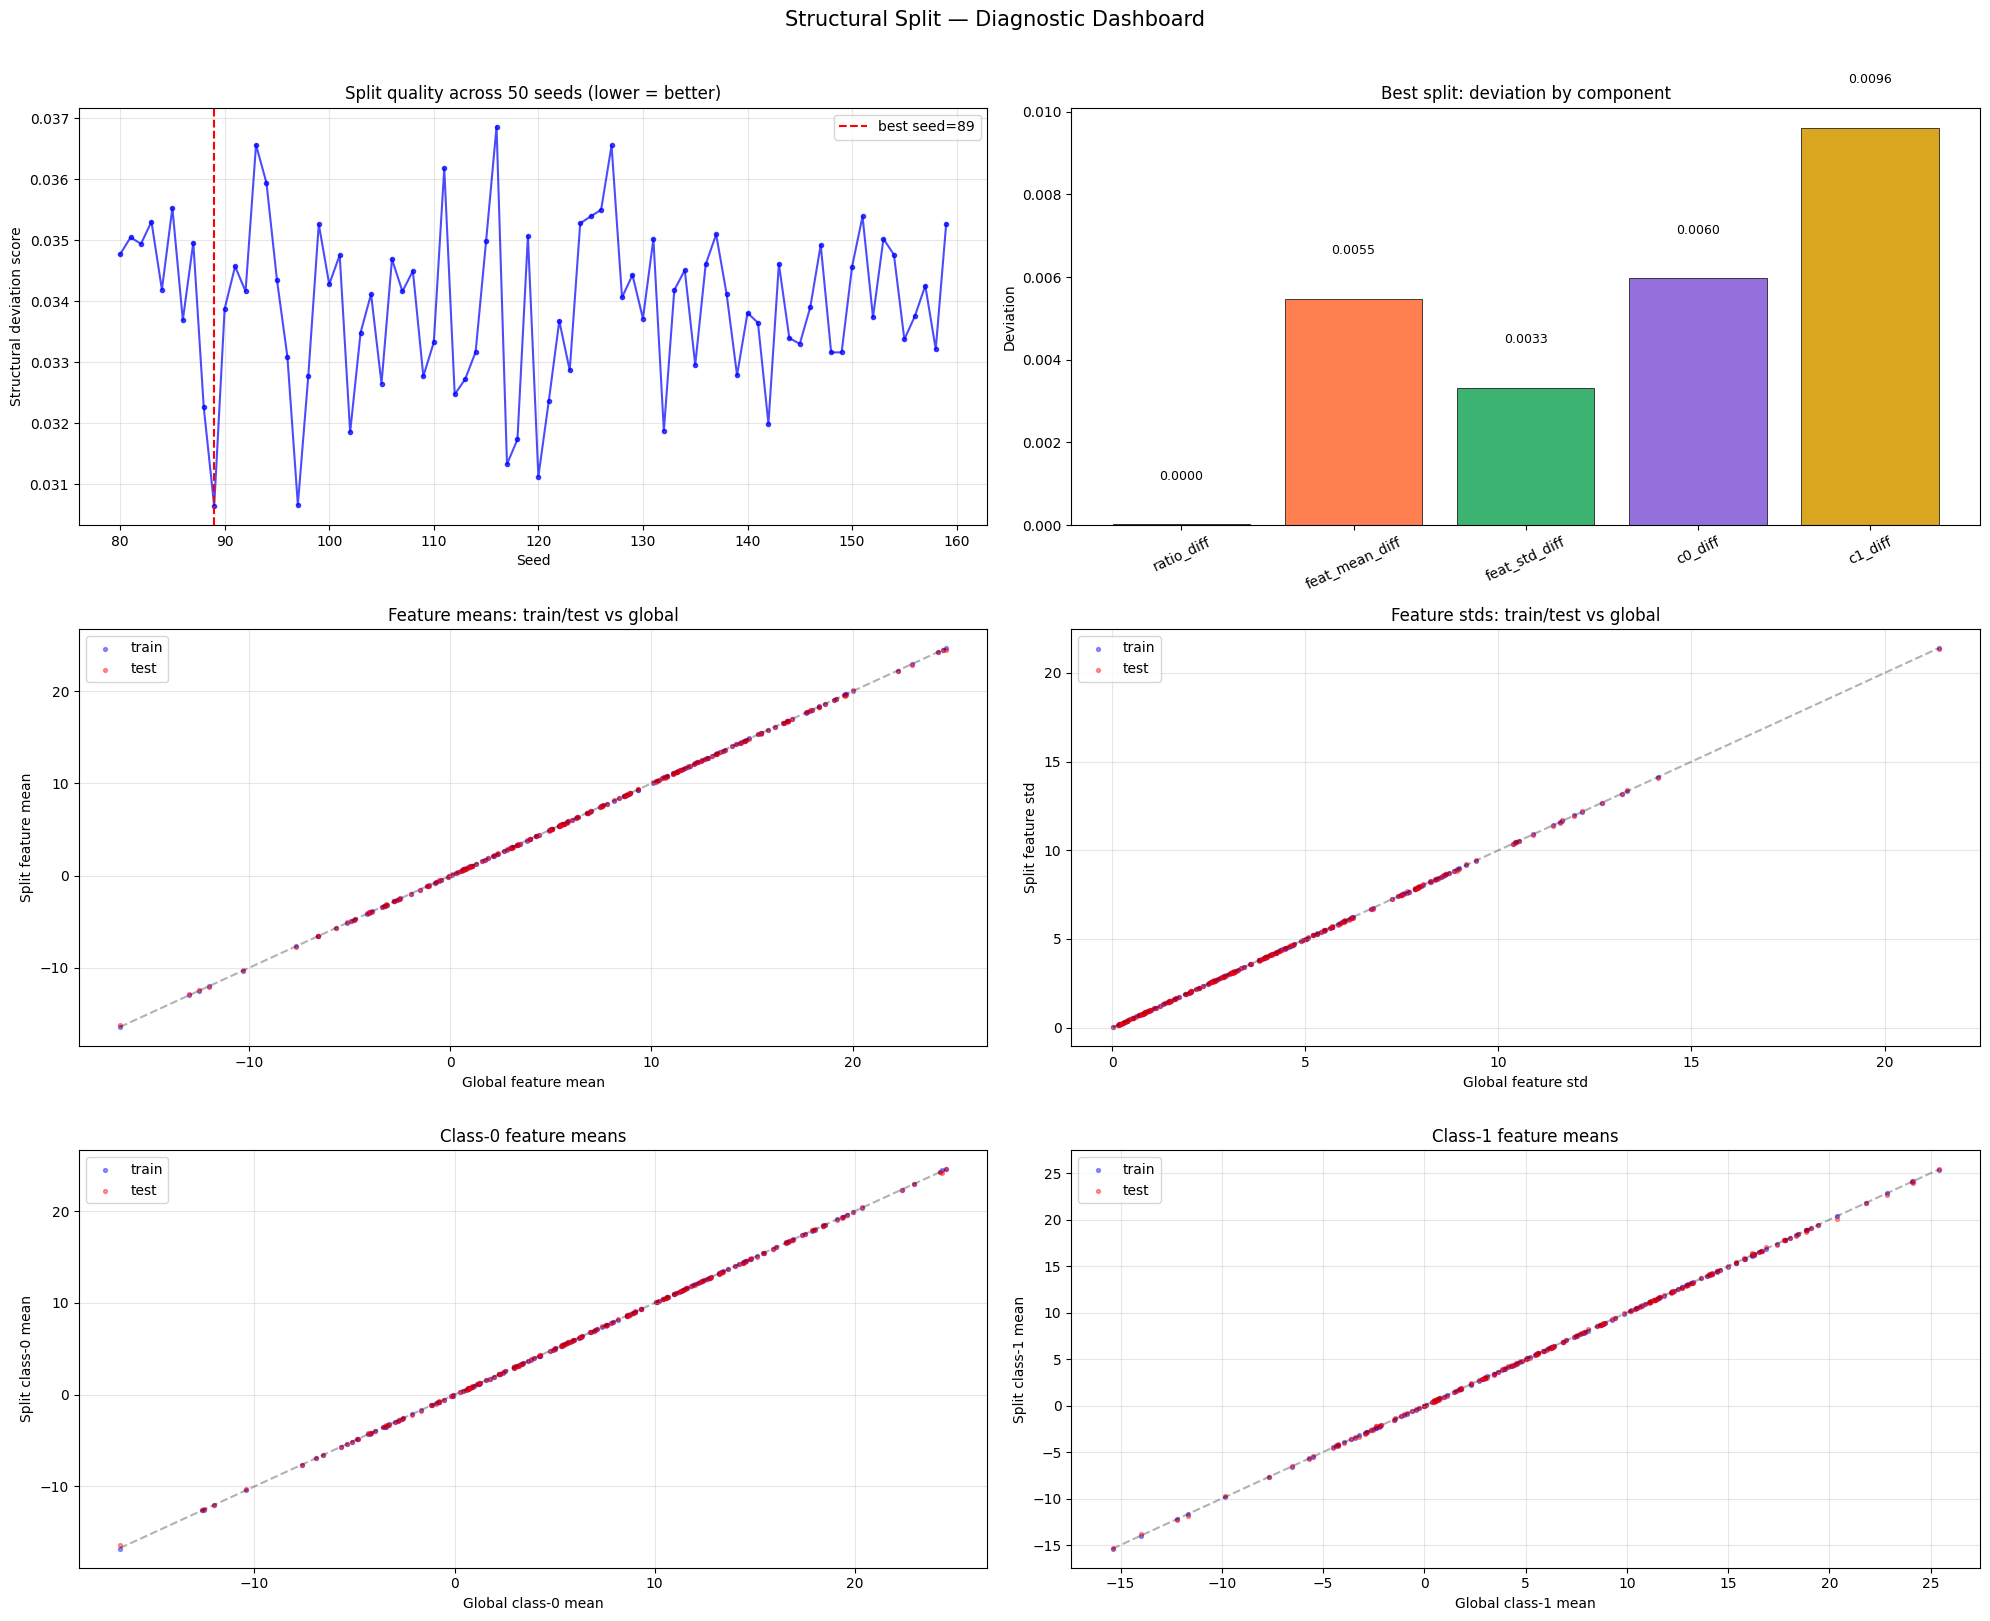

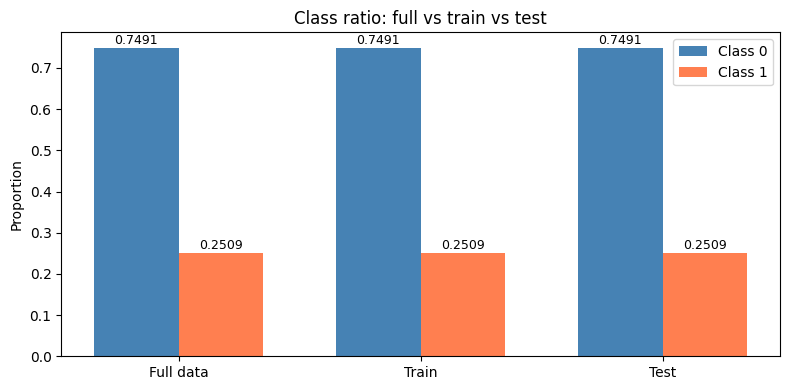

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# ====================== FIND BEST STRUCTURAL SPLIT ======================

def score_split(X, y, X_tr, X_te, y_tr, y_te):
    """Score how well split preserves data structure. Lower = better."""
    global_mean = X.mean(axis=0)
    global_std = X.std(axis=0) + 1e-8

    # class ratio
    ratio_diff = abs(y_tr.mean() - y_te.mean())

    # feature means
    tr_mean_diff = np.abs(X_tr.mean(axis=0) - global_mean) / global_std
    te_mean_diff = np.abs(X_te.mean(axis=0) - global_mean) / global_std
    feat_mean_diff = max(tr_mean_diff.mean(), te_mean_diff.mean())

    # feature stds
    tr_std_ratio = np.abs(X_tr.std(axis=0) / global_std - 1)
    te_std_ratio = np.abs(X_te.std(axis=0) / global_std - 1)
    feat_std_diff = max(tr_std_ratio.mean(), te_std_ratio.mean())

    # class-conditional means
    c0_global = X[y == 0].mean(axis=0)
    c1_global = X[y == 1].mean(axis=0)

    c0_tr_diff = np.abs(X_tr[y_tr == 0].mean(axis=0) - c0_global).mean() / global_std.mean()
    c0_te_diff = np.abs(X_te[y_te == 0].mean(axis=0) - c0_global).mean() / global_std.mean()
    c1_tr_diff = np.abs(X_tr[y_tr == 1].mean(axis=0) - c1_global).mean() / global_std.mean()
    c1_te_diff = np.abs(X_te[y_te == 1].mean(axis=0) - c1_global).mean() / global_std.mean()

    total = (ratio_diff * 100 + feat_mean_diff + feat_std_diff +
             c0_tr_diff + c0_te_diff + c1_tr_diff + c1_te_diff)

    details = {
        'ratio_diff': ratio_diff,
        'feat_mean_diff': feat_mean_diff,
        'feat_std_diff': feat_std_diff,
        'c0_diff': max(c0_tr_diff, c0_te_diff),
        'c1_diff': max(c1_tr_diff, c1_te_diff),
        'total': total
    }
    return total, details


print("\n===== Searching for best structural split =====")

best = {'score': float('inf')}
split_history = []

for seed in range(80, 160):  # try 50 seeds
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_all, y_all, test_size=0.2, random_state=seed, stratify=y_all
    )
    total, details = score_split(X_all, y_all, X_tr, X_te, y_tr, y_te)
    split_history.append({'seed': seed, **details})

    if total < best['score']:
        best = {
            'score': total, 'seed': seed, 'details': details,
            'X_tr': X_tr, 'X_te': X_te, 'y_tr': y_tr, 'y_te': y_te
        }

print(f"\n  Tried 50 seeds")
print(f"  Best seed: {best['seed']}")
print(f"  Score:     {best['score']:.5f}")
print(f"  Details:")
for k, v in best['details'].items():
    print(f"    {k:20s} = {v:.5f}")


# ====================== LOCK THE SPLIT ======================

X_train = best['X_tr']
X_test_split = best['X_te']
y_train = best['y_tr']
y_test = best['y_te']

# scale (fit on train only)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test_split)

print(f"\n===== LOCKED SPLIT =====")
print(f"  X_train: {X_train_sc.shape}  y_train: {y_train.shape}  (pos rate: {y_train.mean():.5f})")
print(f"  X_test:  {X_test_sc.shape}  y_test:  {y_test.shape}  (pos rate: {y_test.mean():.5f})")
print(f"  All models use these variables. No moving parts.")


# ====================== DIAGRAMS ======================

fig = plt.figure(figsize=(20, 16))

# ---- 1. Split quality across seeds ----
ax1 = fig.add_subplot(3, 2, 1)
df_hist = pd.DataFrame(split_history)
ax1.plot(df_hist['seed'], df_hist['total'], 'b-o', markersize=3, alpha=0.7)
ax1.axvline(x=best['seed'], color='red', linestyle='--', label=f"best seed={best['seed']}")
ax1.set_xlabel('Seed')
ax1.set_ylabel('Structural deviation score')
ax1.set_title('Split quality across 50 seeds (lower = better)')
ax1.legend()
ax1.grid(alpha=0.3)

# ---- 2. Score components for best split ----
ax2 = fig.add_subplot(3, 2, 2)
components = ['ratio_diff', 'feat_mean_diff', 'feat_std_diff', 'c0_diff', 'c1_diff']
values = [best['details'][c] for c in components]
colors = ['steelblue', 'coral', 'mediumseagreen', 'mediumpurple', 'goldenrod']
bars = ax2.bar(components, values, color=colors, edgecolor='black', linewidth=0.5)
ax2.set_ylabel('Deviation')
ax2.set_title('Best split: deviation by component')
for bar, val in zip(bars, values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
             f'{val:.4f}', ha='center', va='bottom', fontsize=9)
ax2.tick_params(axis='x', rotation=25)

# ---- 3. Feature means: train/test vs global ----
ax3 = fig.add_subplot(3, 2, 3)
global_mean = X_all.mean(axis=0)
ax3.scatter(global_mean, X_train.mean(axis=0), s=8, alpha=0.4, label='train', color='blue')
ax3.scatter(global_mean, X_test_split.mean(axis=0), s=8, alpha=0.4, label='test', color='red')
lims = [global_mean.min(), global_mean.max()]
ax3.plot(lims, lims, 'k--', alpha=0.3)
ax3.set_xlabel('Global feature mean')
ax3.set_ylabel('Split feature mean')
ax3.set_title('Feature means: train/test vs global')
ax3.legend()
ax3.grid(alpha=0.3)

# ---- 4. Feature stds: train/test vs global ----
ax4 = fig.add_subplot(3, 2, 4)
global_std = X_all.std(axis=0)
ax4.scatter(global_std, X_train.std(axis=0), s=8, alpha=0.4, label='train', color='blue')
ax4.scatter(global_std, X_test_split.std(axis=0), s=8, alpha=0.4, label='test', color='red')
lims = [global_std.min(), global_std.max()]
ax4.plot(lims, lims, 'k--', alpha=0.3)
ax4.set_xlabel('Global feature std')
ax4.set_ylabel('Split feature std')
ax4.set_title('Feature stds: train/test vs global')
ax4.legend()
ax4.grid(alpha=0.3)

# ---- 5. Class-conditional means: class 0 ----
ax5 = fig.add_subplot(3, 2, 5)
c0_global = X_all[y_all == 0].mean(axis=0)
c0_train = X_train[y_train == 0].mean(axis=0)
c0_test = X_test_split[y_test == 0].mean(axis=0)
ax5.scatter(c0_global, c0_train, s=8, alpha=0.4, label='train', color='blue')
ax5.scatter(c0_global, c0_test, s=8, alpha=0.4, label='test', color='red')
lims = [c0_global.min(), c0_global.max()]
ax5.plot(lims, lims, 'k--', alpha=0.3)
ax5.set_xlabel('Global class-0 mean')
ax5.set_ylabel('Split class-0 mean')
ax5.set_title('Class-0 feature means')
ax5.legend()
ax5.grid(alpha=0.3)

# ---- 6. Class-conditional means: class 1 ----
ax6 = fig.add_subplot(3, 2, 6)
c1_global = X_all[y_all == 1].mean(axis=0)
c1_train = X_train[y_train == 1].mean(axis=0)
c1_test = X_test_split[y_test == 1].mean(axis=0)
ax6.scatter(c1_global, c1_train, s=8, alpha=0.4, label='train', color='blue')
ax6.scatter(c1_global, c1_test, s=8, alpha=0.4, label='test', color='red')
lims = [c1_global.min(), c1_global.max()]
ax6.plot(lims, lims, 'k--', alpha=0.3)
ax6.set_xlabel('Global class-1 mean')
ax6.set_ylabel('Split class-1 mean')
ax6.set_title('Class-1 feature means')
ax6.legend()
ax6.grid(alpha=0.3)

plt.suptitle('Structural Split — Diagnostic Dashboard', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

# ---- extra: class ratio comparison ----
fig2, ax = plt.subplots(figsize=(8, 4))
labels = ['Full data', 'Train', 'Test']
pos_rates = [y_all.mean(), y_train.mean(), y_test.mean()]
neg_rates = [1 - y_all.mean(), 1 - y_train.mean(), 1 - y_test.mean()]

x = np.arange(len(labels))
width = 0.35
ax.bar(x - width/2, neg_rates, width, label='Class 0', color='steelblue')
ax.bar(x + width/2, pos_rates, width, label='Class 1', color='coral')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Proportion')
ax.set_title('Class ratio: full vs train vs test')
ax.legend()

for i, (n, p) in enumerate(zip(neg_rates, pos_rates)):
    ax.text(i - width/2, n + 0.01, f'{n:.4f}', ha='center', fontsize=9)
    ax.text(i + width/2, p + 0.01, f'{p:.4f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

In [3]:
# ====================== BAYESIAN HYPERPARAMETER TUNING (OPTUNA) ======================
# Uses locked split from previous cell:
#   X_train_sc, y_train  (for training + internal CV)
#   X_test_sc, y_test    (locked meta-val for final evaluation)

import numpy as np
import pandas as pd
import pickle
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import optuna
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import roc_curve, auc, accuracy_score, f1_score, precision_score, recall_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)

print(f"X_train_sc: {X_train_sc.shape}  y_train: {y_train.shape}")
print(f"X_test_sc:  {X_test_sc.shape}  y_test: {y_test.shape}")


# ====================== HELPERS ======================

def best_threshold_metrics(y_true, scores):
    fpr, tpr, thr_arr = roc_curve(y_true, scores)
    J = tpr - fpr
    idx = int(np.argmax(J))
    thr = thr_arr[idx]
    y_pred = (scores >= thr).astype(int)
    return {
        'best_thr': thr,
        'auc_binary': (1 + tpr[idx] - fpr[idx]) / 2,
        'acc': accuracy_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
        'prec': precision_score(y_true, y_pred),
        'rec': recall_score(y_true, y_pred),
    }


def cv_auc(model, X, y, n_folds=3, seed=42):
    """3-fold CV AUC within training data (for Optuna objective)."""
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    aucs = []
    for tr_idx, val_idx in skf.split(X, y):
        model.fit(X[tr_idx], y[tr_idx])
        scores = model.predict_proba(X[val_idx])[:, 1]
        aucs.append(auc(*roc_curve(y[val_idx], scores)[:2]))
    return np.mean(aucs)


# KNN subsample for speed (KNN is O(n^2) for prediction)
knn_n = min(25000, len(y_train))
knn_idx = np.random.RandomState(42).choice(len(y_train), knn_n, replace=False)
X_knn = X_train_sc[knn_idx]
y_knn = y_train[knn_idx]
print(f"\nKNN tuning subsample: {X_knn.shape}")

# RBF subsample (PyTorch training speed)
rbf_n = min(50000, len(y_train))
rbf_idx = np.random.RandomState(42).choice(len(y_train), rbf_n, replace=False)
X_rbf = X_train_sc[rbf_idx]
y_rbf = y_train[rbf_idx]
print(f"RBF tuning subsample: {X_rbf.shape}")


# ====================== 1. GNB ======================

def gnb_objective(trial):
    vs = trial.suggest_float('var_smoothing', 1e-11, 1e-2, log=True)
    m = GaussianNB(var_smoothing=vs)
    return cv_auc(m, X_train_sc, y_train)


# ====================== 2. KNN LDA-1 ======================

def knn_lda_objective(trial):
    k = trial.suggest_int('k', 50, 1000)
    weights = trial.suggest_categorical('weights', ['uniform', 'distance'])

    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    aucs = []
    for tr_idx, val_idx in skf.split(X_knn, y_knn):
        lda = LinearDiscriminantAnalysis(solver='svd')
        Xtr_lda = lda.fit_transform(X_knn[tr_idx], y_knn[tr_idx])
        Xval_lda = lda.transform(X_knn[val_idx])

        m = KNeighborsClassifier(n_neighbors=min(k, len(tr_idx)), weights=weights, n_jobs=-1)
        m.fit(Xtr_lda, y_knn[tr_idx])
        scores = m.predict_proba(Xval_lda)[:, 1]
        aucs.append(auc(*roc_curve(y_knn[val_idx], scores)[:2]))
    return np.mean(aucs)


# ====================== 3. KNN PLS-DA ======================

def knn_pls_objective(trial):
    k = trial.suggest_int('k', 50, 1000)
    n_comp = trial.suggest_int('n_components', 5, 50)
    weights = trial.suggest_categorical('weights', ['uniform', 'distance'])

    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    aucs = []
    for tr_idx, val_idx in skf.split(X_knn, y_knn):
        pls = PLSRegression(n_components=n_comp, scale=False)
        Xtr_pls = pls.fit_transform(X_knn[tr_idx], y_knn[tr_idx].reshape(-1, 1))[0]
        Xval_pls = pls.transform(X_knn[val_idx])

        m = KNeighborsClassifier(n_neighbors=min(k, len(tr_idx)), weights=weights, n_jobs=-1)
        m.fit(Xtr_pls, y_knn[tr_idx])
        scores = m.predict_proba(Xval_pls)[:, 1]
        aucs.append(auc(*roc_curve(y_knn[val_idx], scores)[:2]))
    return np.mean(aucs)


# ====================== 4. KNN PCA ======================

def knn_pca_objective(trial):
    k = trial.suggest_int('k', 50, 1000)
    n_comp = trial.suggest_int('n_components', 5, 50)
    weights = trial.suggest_categorical('weights', ['uniform', 'distance'])

    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    aucs = []
    for tr_idx, val_idx in skf.split(X_knn, y_knn):
        pca = PCA(n_components=n_comp, random_state=42)
        Xtr_pca = pca.fit_transform(X_knn[tr_idx])
        Xval_pca = pca.transform(X_knn[val_idx])

        m = KNeighborsClassifier(n_neighbors=min(k, len(tr_idx)), weights=weights, n_jobs=-1)
        m.fit(Xtr_pca, y_knn[tr_idx])
        scores = m.predict_proba(Xval_pca)[:, 1]
        aucs.append(auc(*roc_curve(y_knn[val_idx], scores)[:2]))
    return np.mean(aucs)


# ====================== 5. ElasticNet LR ======================

def elasticnet_objective(trial):
    C = trial.suggest_float('C', 0.01, 100, log=True)
    l1_ratio = trial.suggest_float('l1_ratio', 0.05, 0.95)
    m = LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=l1_ratio,
                           C=C, max_iter=2000, tol=1e-3, random_state=42)
    return cv_auc(m, X_train_sc, y_train)


# ====================== 6. LDA ======================

def lda_objective(trial):
    shrinkage = trial.suggest_float('shrinkage', 0.0, 1.0)
    m = LinearDiscriminantAnalysis(solver='lsqr', shrinkage=shrinkage)
    return cv_auc(m, X_train_sc, y_train)


# ====================== 7. XGBoost ======================

def xgboost_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
    }
    m = XGBClassifier(**params, tree_method='hist', eval_metric='auc',
                      n_jobs=-1, random_state=42, verbosity=0)
    return cv_auc(m, X_train_sc, y_train)


# ====================== 8. LightGBM ======================

def lightgbm_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 200),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10, log=True),
    }
    m = LGBMClassifier(**params, is_unbalance=True,
                       n_jobs=-1, random_state=42, verbose=-1)
    return cv_auc(m, X_train_sc, y_train)


# ====================== 9. RBF NETWORK ======================

class RBFLayer(nn.Module):
    def __init__(self, n_input, n_rbf, X_init):
        super().__init__()
        idx = np.random.RandomState(42).choice(len(X_init), n_rbf, replace=False)
        centers = torch.FloatTensor(X_init[idx])
        self.centers = nn.Parameter(centers)
        with torch.no_grad():
            d = torch.cdist(centers, centers)
            med_dist = d.median().item()
        self.log_sigma = nn.Parameter(torch.ones(n_rbf) * np.log(med_dist / 2 + 1e-8))

    def forward(self, x):
        d2 = torch.cdist(x, self.centers, p=2).pow(2)
        sigma2 = torch.exp(2 * self.log_sigma).unsqueeze(0)
        return torch.exp(-d2 / (2 * sigma2))


class RBFNetwork(nn.Module):
    def __init__(self, n_input, n_rbf, X_init):
        super().__init__()
        self.rbf = RBFLayer(n_input, n_rbf, X_init)
        self.output = nn.Linear(n_rbf, 1)

    def forward(self, x):
        return self.output(self.rbf(x)).squeeze(-1)


def rbf_objective(trial):
    n_rbf = trial.suggest_int('n_rbf', 128, 512, step=64)
    lr = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    epochs = trial.suggest_int('epochs', 20, 60, step=10)

    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    aucs = []

    for tr_idx, val_idx in skf.split(X_rbf, y_rbf):
        Xtr = X_rbf[tr_idx]
        Xval = X_rbf[val_idx]
        ytr = y_rbf[tr_idx]
        yval = y_rbf[val_idx]

        torch.manual_seed(42)
        model = RBFNetwork(n_input=Xtr.shape[1], n_rbf=n_rbf, X_init=Xtr)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([9.0]))

        Xtr_t = torch.FloatTensor(Xtr)
        ytr_t = torch.FloatTensor(ytr)
        Xval_t = torch.FloatTensor(Xval)

        dl = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=2048, shuffle=True)

        for _ in range(epochs):
            model.train()
            for Xb, yb in dl:
                optimizer.zero_grad()
                loss = criterion(model(Xb), yb)
                loss.backward()
                optimizer.step()

        model.eval()
        with torch.no_grad():
            scores = torch.sigmoid(model(Xval_t)).numpy()
        aucs.append(auc(*roc_curve(yval, scores)[:2]))

    return np.mean(aucs)


# ====================== RUN ALL STUDIES ======================

studies = {
    'GNB':           (gnb_objective, 20),
    'KNN_LDA1':      (knn_lda_objective, 15),
    'KNN_PLS30':     (knn_pls_objective, 15),
    'KNN_PCA30':     (knn_pca_objective, 15),
    'ElasticNet_LR': (elasticnet_objective, 25),
    'LDA':           (lda_objective, 15),
    'XGBoost':       (xgboost_objective, 40),
    'LightGBM':      (lightgbm_objective, 40),
    'RBF_Network':   (rbf_objective, 15),
}

best_configs = {}

for name, (objective, n_trials) in studies.items():
    print(f"\n{'='*85}")
    print(f"  TUNING: {name}  ({n_trials} trials)")
    print(f"{'='*85}")

    t0 = time.time()
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=42)
    )
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)

    elapsed = time.time() - t0
    best_cv = study.best_value

    print(f"  Best CV AUC: {best_cv:.4f}  ({elapsed:.1f}s)")
    print(f"  Best params: {study.best_params}")

    best_configs[name] = {
        'best_params': study.best_params,
        'cv_auc': best_cv,
    }


# ====================== EVALUATE ALL BEST CONFIGS ON META-VAL ======================

print(f"\n{'='*85}")
print("EVALUATION ON LOCKED META-VAL (X_test_sc)")
print(f"{'='*85}")

results = []

for name, cfg in best_configs.items():
    p = cfg['best_params']
    print(f"\n  {name}...")

    if name == 'GNB':
        m = GaussianNB(var_smoothing=p['var_smoothing'])
        m.fit(X_train_sc, y_train)
        scores = m.predict_proba(X_test_sc)[:, 1]

    elif name == 'KNN_LDA1':
        lda = LinearDiscriminantAnalysis(solver='svd')
        Xtr_lda = lda.fit_transform(X_train_sc, y_train)
        Xte_lda = lda.transform(X_test_sc)
        m = KNeighborsClassifier(n_neighbors=p['k'], weights=p['weights'], n_jobs=-1)
        m.fit(Xtr_lda, y_train)
        scores = m.predict_proba(Xte_lda)[:, 1]

    elif name == 'KNN_PLS30':
        pls = PLSRegression(n_components=p['n_components'], scale=False)
        Xtr_pls = pls.fit_transform(X_train_sc, y_train.reshape(-1, 1))[0]
        Xte_pls = pls.transform(X_test_sc)
        m = KNeighborsClassifier(n_neighbors=p['k'], weights=p['weights'], n_jobs=-1)
        m.fit(Xtr_pls, y_train)
        scores = m.predict_proba(Xte_pls)[:, 1]

    elif name == 'KNN_PCA30':
        pca = PCA(n_components=p['n_components'], random_state=42)
        Xtr_pca = pca.fit_transform(X_train_sc)
        Xte_pca = pca.transform(X_test_sc)
        m = KNeighborsClassifier(n_neighbors=p['k'], weights=p['weights'], n_jobs=-1)
        m.fit(Xtr_pca, y_train)
        scores = m.predict_proba(Xte_pca)[:, 1]

    elif name == 'ElasticNet_LR':
        m = LogisticRegression(penalty='elasticnet', solver='saga',
                               l1_ratio=p['l1_ratio'], C=p['C'],
                               max_iter=2000, tol=1e-3, random_state=42)
        m.fit(X_train_sc, y_train)
        scores = m.predict_proba(X_test_sc)[:, 1]

    elif name == 'LDA':
        m = LinearDiscriminantAnalysis(solver='lsqr', shrinkage=p['shrinkage'])
        m.fit(X_train_sc, y_train)
        scores = m.predict_proba(X_test_sc)[:, 1]

    elif name == 'XGBoost':
        m = XGBClassifier(**p, tree_method='hist', eval_metric='auc',
                          n_jobs=-1, random_state=42, verbosity=0)
        m.fit(X_train_sc, y_train)
        scores = m.predict_proba(X_test_sc)[:, 1]

    elif name == 'LightGBM':
        m = LGBMClassifier(**p, is_unbalance=True,
                           n_jobs=-1, random_state=42, verbose=-1)
        m.fit(X_train_sc, y_train)
        scores = m.predict_proba(X_test_sc)[:, 1]

    elif name == 'RBF_Network':
        torch.manual_seed(42)
        model = RBFNetwork(n_input=X_train_sc.shape[1], n_rbf=p['n_rbf'],
                           X_init=X_train_sc)
        optimizer = torch.optim.Adam(model.parameters(), lr=p['lr'])
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([9.0]))
        dl = DataLoader(TensorDataset(torch.FloatTensor(X_train_sc),
                                       torch.FloatTensor(y_train)),
                        batch_size=2048, shuffle=True)
        for _ in range(p['epochs']):
            model.train()
            for Xb, yb in dl:
                optimizer.zero_grad()
                loss = criterion(model(Xb), yb)
                loss.backward()
                optimizer.step()
        model.eval()
        with torch.no_grad():
            scores = torch.sigmoid(model(torch.FloatTensor(X_test_sc))).numpy()

    # metrics
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc_prob = auc(fpr, tpr)
    m = best_threshold_metrics(y_test, scores)

    results.append({
        'model': name,
        'cv_auc': cfg['cv_auc'],
        'meta_val_auc_prob': auc_prob,
        'meta_val_auc_bin': m['auc_binary'],
        'best_thr': m['best_thr'],
        'f1': m['f1'],
        'prec': m['prec'],
        'rec': m['rec'],
    })

    best_configs[name]['meta_val_auc_prob'] = auc_prob
    best_configs[name]['meta_val_auc_bin'] = m['auc_binary']
    best_configs[name]['best_thr'] = m['best_thr']

    print(f"    CV AUC={cfg['cv_auc']:.4f}  Meta-val AUC_prob={auc_prob:.4f}  "
          f"AUC_bin={m['auc_binary']:.4f}  f1={m['f1']:.4f}")


# ====================== SAVE PICKLE ======================

with open('best_model_configs.pkl', 'wb') as f:
    pickle.dump(best_configs, f)

print(f"\n  Saved: best_model_configs.pkl")


# ====================== SUMMARY TABLE ======================

df_res = pd.DataFrame(results).sort_values('meta_val_auc_bin', ascending=False)

print(f"\n{'='*105}")
print("TUNED MODELS — ranked by binary AUC on locked meta-val")
print(f"{'='*105}")
print(df_res.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print(f"\n  Pickle saved with best params for all {len(best_configs)} models")
print(f"  Load with: configs = pickle.load(open('best_model_configs.pkl', 'rb'))")
print(f"{'='*105}")

X_train_sc: (64078, 200)  y_train: (64078,)
X_test_sc:  (16020, 200)  y_test: (16020,)

KNN tuning subsample: (25000, 200)
RBF tuning subsample: (50000, 200)

  TUNING: GNB  (20 trials)
  Best CV AUC: 0.8869  (9.0s)
  Best params: {'var_smoothing': 4.384830441635468e-06}

  TUNING: KNN_LDA1  (15 trials)
  Best CV AUC: 0.8581  (41.0s)
  Best params: {'k': 891, 'weights': 'uniform'}

  TUNING: KNN_PLS30  (15 trials)


/usr/local/lib/python3.13/dist-packages/sklearn/cross_decomposition/_pls.py:365: RuntimeWarning: invalid value encountered in divide
  y_scores = np.dot(yk, y_weights) / y_ss
/usr/local/lib/python3.13/dist-packages/sklearn/cross_decomposition/_pls.py:365: RuntimeWarning: invalid value encountered in divide
  y_scores = np.dot(yk, y_weights) / y_ss
/usr/local/lib/python3.13/dist-packages/sklearn/cross_decomposition/_pls.py:365: RuntimeWarning: invalid value encountered in divide
  y_scores = np.dot(yk, y_weights) / y_ss
/usr/local/lib/python3.13/dist-packages/sklearn/cross_decomposition/_pls.py:365: RuntimeWarning: invalid value encountered in divide
  y_scores = np.dot(yk, y_weights) / y_ss
/usr/local/lib/python3.13/dist-packages/sklearn/cross_decomposition/_pls.py:365: RuntimeWarning: invalid value encountered in divide
  y_scores = np.dot(yk, y_weights) / y_ss
/usr/local/lib/python3.13/dist-packages/sklearn/cross_decomposition/_pls.py:365: RuntimeWarning: invalid value encountered in

  Best CV AUC: 0.8577  (116.2s)
  Best params: {'k': 994, 'n_components': 48, 'weights': 'uniform'}

  TUNING: KNN_PCA30  (15 trials)
  Best CV AUC: 0.8527  (97.4s)
  Best params: {'k': 953, 'n_components': 44, 'weights': 'uniform'}

  TUNING: ElasticNet_LR  (25 trials)
  Best CV AUC: 0.8569  (161.6s)
  Best params: {'C': 0.010762007504795744, 'l1_ratio': 0.055261281718056394}

  TUNING: LDA  (15 trials)
  Best CV AUC: 0.8577  (13.9s)
  Best params: {'shrinkage': 0.990698406375494}

  TUNING: XGBoost  (40 trials)
  Best CV AUC: 0.8872  (2152.6s)
  Best params: {'n_estimators': 864, 'max_depth': 3, 'learning_rate': 0.12421403725415253, 'subsample': 0.9978290036058436, 'colsample_bytree': 0.6493292618091767, 'reg_alpha': 0.017311174144816786, 'reg_lambda': 0.002739732630680926, 'min_child_weight': 9}

  TUNING: LightGBM  (40 trials)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

  Best CV AUC: 0.8868  (1043.7s)
  Best params: {'n_estimators': 848, 'max_depth': 3, 'learning_rate': 0.1155449771997403, 'num_leaves': 130, 'subsample': 0.6895236240011603, 'colsample_bytree': 0.9820834860601049, 'min_child_samples': 56, 'reg_alpha': 0.006806549023467636, 'reg_lambda': 1.307265412848197}

  TUNING: RBF_Network  (15 trials)
  Best CV AUC: 0.8787  (672.5s)
  Best params: {'n_rbf': 128, 'lr': 0.005399484409787433, 'epochs': 50}

EVALUATION ON LOCKED META-VAL (X_test_sc)

  GNB...
    CV AUC=0.8869  Meta-val AUC_prob=0.8887  AUC_bin=0.8102  f1=0.6900

  KNN_LDA1...
    CV AUC=0.8581  Meta-val AUC_prob=0.8619  AUC_bin=0.7837  f1=0.6485

  KNN_PLS30...


/usr/local/lib/python3.13/dist-packages/sklearn/cross_decomposition/_pls.py:365: RuntimeWarning: invalid value encountered in divide
  y_scores = np.dot(yk, y_weights) / y_ss


    CV AUC=0.8577  Meta-val AUC_prob=0.8631  AUC_bin=0.7838  f1=0.6418

  KNN_PCA30...
    CV AUC=0.8527  Meta-val AUC_prob=0.8612  AUC_bin=0.7829  f1=0.6469

  ElasticNet_LR...
    CV AUC=0.8569  Meta-val AUC_prob=0.8619  AUC_bin=0.7839  f1=0.6463

  LDA...
    CV AUC=0.8577  Meta-val AUC_prob=0.8624  AUC_bin=0.7842  f1=0.6456

  XGBoost...
    CV AUC=0.8872  Meta-val AUC_prob=0.8907  AUC_bin=0.8083  f1=0.6937

  LightGBM...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


    CV AUC=0.8868  Meta-val AUC_prob=0.8885  AUC_bin=0.8081  f1=0.6804

  RBF_Network...
    CV AUC=0.8787  Meta-val AUC_prob=0.8811  AUC_bin=0.8016  f1=0.6722

  Saved: best_model_configs.pkl

TUNED MODELS — ranked by binary AUC on locked meta-val
        model  cv_auc  meta_val_auc_prob  meta_val_auc_bin  best_thr     f1   prec    rec
          GNB  0.8869             0.8887            0.8102    0.2821 0.6900 0.6159 0.7843
      XGBoost  0.8872             0.8907            0.8083    0.2946 0.6937 0.6360 0.7629
     LightGBM  0.8868             0.8885            0.8081    0.4490 0.6804 0.5904 0.8027
  RBF_Network  0.8787             0.8811            0.8016    0.7972 0.6722 0.5835 0.7928
          LDA  0.8577             0.8624            0.7842    0.2503 0.6456 0.5482 0.7851
ElasticNet_LR  0.8569             0.8619            0.7839    0.2571 0.6463 0.5517 0.7801
    KNN_PLS30  0.8577             0.8631            0.7838    0.1932 0.6418 0.5363 0.7990
     KNN_LDA1  0.8581          